# Saliency map randomization experiment


## 1. Load the model and upload photos

In [28]:
from copy import deepcopy
from io import BytesIO

import matplotlib.pyplot as plt
import pandas as pd
import torch
from google.colab import files
from PIL import Image, ImageOps
from scipy.stats import spearmanr
from torchvision.models import ResNet18_Weights, resnet18

SEEDS = [42, 44, 46]

weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).eval()
preprocess = weights.transforms()

uploaded = files.upload()
if not uploaded:
    raise ValueError("Upload at least one JPG or PNG image.")

print(f"Loaded {len(uploaded)} image(s).")

Saving 7_04dac2d6-069f-4d02-b36f-5fc94fc3c868.webp to 7_04dac2d6-069f-4d02-b36f-5fc94fc3c868.webp
Saving banana.jpg to banana.jpg
Saving bird.jpg to bird.jpg
Saving dog_photo.png to dog_photo (2).png
Loaded 4 image(s).


## 2. Run the experiment

Each photo keeps the class predicted by the pretrained model throughout the cascade. Every reset stage is compared with the original maps for that photo.

In [29]:
def make_gradcam(model_to_test, input_batch, target_class):
    captured = []

    def save_maps(module, inputs, output):
        captured.append(output)

    hook = model_to_test.layer4[-1].register_forward_hook(save_maps)
    scores = model_to_test(input_batch)
    hook.remove()

    maps = captured[0]
    score = scores[0, target_class]
    gradients = torch.autograd.grad(score, maps)[0]
    weights = gradients.mean(dim=(2, 3), keepdim=True)

    return (maps.detach() * weights).sum(dim=1).relu()[0]


def keep_positive_gradients(module, grad_input, grad_output):
    return (grad_input[0].clamp(min=0),)


def make_guided_gradients(model_to_test, input_batch, target_class):
    guided_copy = deepcopy(model_to_test)
    image_for_gradients = input_batch.detach().clone().requires_grad_(True)

    hooks = []
    for layer in guided_copy.modules():
        if isinstance(layer, torch.nn.ReLU):
            layer.inplace = False
            hooks.append(
                layer.register_full_backward_hook(keep_positive_gradients)
            )

    score = guided_copy(image_for_gradients)[0, target_class]
    gradients = torch.autograd.grad(score, image_for_gradients)[0]

    for hook in hooks:
        hook.remove()

    return gradients


def rank_similarity(before, after):
    before_values = before.detach().cpu().flatten().numpy()
    after_values = after.detach().cpu().flatten().numpy()
    if before_values.min() == before_values.max() or after_values.min() == after_values.max():
        return float("nan")
    return spearmanr(before_values, after_values)[0]

In [30]:
stages = [
    ("fc", ()),
    ("fc + layer4", ("layer4",)),
    ("+ layer3", ("layer3",)),
    ("+ layer2", ("layer2",)),
    ("+ layer1", ("layer1",)),
    ("+ stem", ("conv1", "bn1")),
]

rows = []
example = {}

for image_name, image_bytes in uploaded.items():
    with Image.open(BytesIO(image_bytes)) as image:
        input_batch = preprocess(ImageOps.exif_transpose(image).convert("RGB")).unsqueeze(0)

    with torch.no_grad():
        target_class = model(input_batch)[0].argmax().item()

    class_name = weights.meta["categories"][target_class]
    print(f"{image_name} → {class_name} ({target_class})")

    original_cam = make_gradcam(model, input_batch, target_class)
    original_guided = make_guided_gradients(model, input_batch, target_class)
    original_magnitude = original_guided.abs()

    for seed in SEEDS:
        # Preserve the initialization used in the original seed-42 pilot.
        torch.manual_seed(seed)
        test_model = deepcopy(model)
        test_model.fc.reset_parameters()

        torch.manual_seed(seed + 1)
        fresh_model = resnet18(weights=None)

        for stage, layer_names in stages:
            for name in layer_names:
                getattr(test_model, name).load_state_dict(
                    getattr(fresh_model, name).state_dict()
                )

            cam = make_gradcam(test_model, input_batch, target_class)
            guided = make_guided_gradients(test_model, input_batch, target_class)
            magnitude = guided.abs()

            rows.append({
                "image": image_name,
                "target_class": target_class,
                "class_name": class_name,
                "seed": seed,
                "stage": stage,
                "gradcam": rank_similarity(original_cam, cam),
                "guided_abs_rgb": rank_similarity(original_magnitude, magnitude),
                "guided_signed_rgb": rank_similarity(original_guided, guided),
            })

            if not example:
                example = {
                    "image": image_name,
                    "class_name": class_name,
                    "before_cam": original_cam,
                    "after_cam": cam,
                    "before_guided": original_magnitude[0].amax(dim=0),
                    "after_guided": magnitude[0].amax(dim=0),
                }

7_04dac2d6-069f-4d02-b36f-5fc94fc3c868.webp → mountain bike (671)
banana.jpg → banana (954)
bird.jpg → bald eagle (22)
dog_photo (2).png → miniature poodle (266)


## 3. Save and inspect results

The CSV has one row per image, seed, and reset stage. Use the Colab Files panel to download `saliency_results.csv` after the run. Correlations for constant maps are undefined and appear as blank CSV values.

Saved 72 rows to saliency_results.csv.


,image,target_class,class_name,seed,stage,gradcam,guided_abs_rgb,guided_signed_rgb
0,7_04dac2d6-069f-4d02-b36f-5fc94fc3c868.webp,671,mountain bike,42,fc,-0.070339,0.996246,0.998838
1,7_04dac2d6-069f-4d02-b36f-5fc94fc3c868.webp,671,mountain bike,42,fc + layer4,0.051031,0.947311,0.982321
2,7_04dac2d6-069f-4d02-b36f-5fc94fc3c868.webp,671,mountain bike,42,+ layer3,NaN,0.859089,0.920766
3,7_04dac2d6-069f-4d02-b36f-5fc94fc3c868.webp,671,mountain bike,42,+ layer2,NaN,0.683226,0.769338
4,7_04dac2d6-069f-4d02-b36f-5fc94fc3c868.webp,671,mountain bike,42,+ layer1,NaN,0.534232,0.565274
...,...,...,...,...,...,...,...,...
67,dog_photo (2).png,266,miniature poodle,46,fc + layer4,NaN,0.941748,0.984420
68,dog_photo (2).png,266,miniature poodle,46,+ layer3,-0.205357,0.634252,0.867406
69,dog_photo (2).png,266,miniature poodle,46,+ layer2,0.058903,0.448468,0.747535
70,dog_photo (2).png,266,miniature poodle,46,+ layer1,0.165462,0.277725,0.564985


Valid correlations per stage:


,gradcam,guided_abs_rgb,guided_signed_rgb
stage,,,
fc,12,12,12
fc + layer4,10,12,12
+ layer3,10,12,12
+ layer2,10,12,12
+ layer1,10,12,12
+ stem,10,12,12


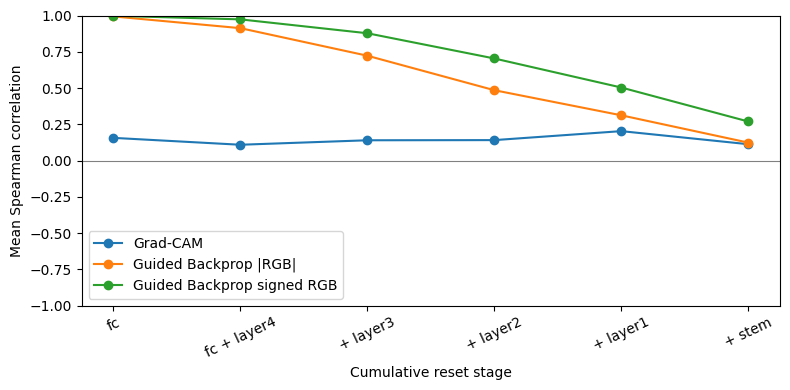

In [31]:
results = pd.DataFrame(rows)
results.to_csv("saliency_results.csv", index=False)
print(f"Saved {len(results)} rows to saliency_results.csv.")
display(results)

metrics = ["gradcam", "guided_abs_rgb", "guided_signed_rgb"]
stage_order = [stage for stage, _ in stages]
labels = ["Grad-CAM", "Guided Backprop |RGB|", "Guided Backprop signed RGB"]
summary = results.groupby("stage")[metrics].mean().reindex(stage_order)
counts = results.groupby("stage")[metrics].count().reindex(stage_order)

if results[metrics].isna().any().any():
    print("Valid correlations per stage:")
    display(counts)

ax = summary.set_axis(labels, axis=1).plot(marker="o", figsize=(8, 4), rot=25)
ax.set_xlabel("Cumulative reset stage")
ax.set_ylabel("Mean Spearman correlation")
ax.set_ylim(-1, 1)
ax.axhline(0, color="gray", linewidth=0.8)
plt.tight_layout()
plt.show()

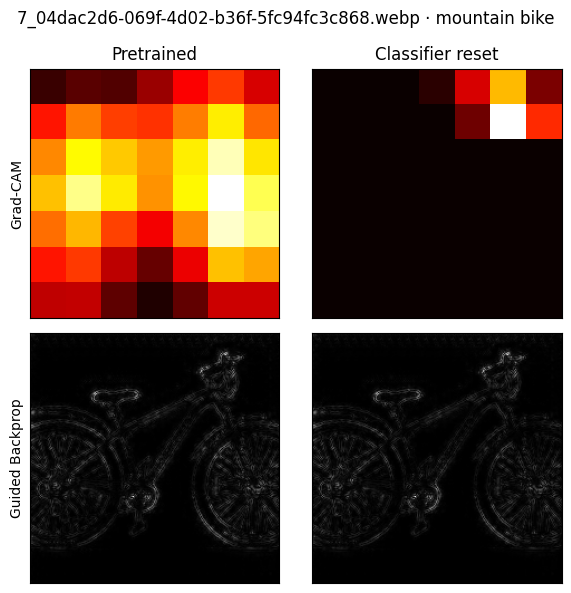

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
fig.suptitle(f"{example['image']} · {example['class_name']}")

axes[0, 0].set_title("Pretrained")
axes[0, 1].set_title("Classifier reset")
axes[0, 0].imshow(example["before_cam"], cmap="hot", interpolation="nearest", vmin=0)
axes[0, 1].imshow(example["after_cam"], cmap="hot", interpolation="nearest", vmin=0)
axes[1, 0].imshow(example["before_guided"], cmap="gray", vmin=0)
axes[1, 1].imshow(example["after_guided"], cmap="gray", vmin=0)

for row_index, label in enumerate(["Grad-CAM", "Guided Backprop"]):
    axes[row_index, 0].set_ylabel(label)
    for axis in axes[row_index]:
        axis.set_xticks([])
        axis.set_yticks([])

plt.tight_layout()
plt.show()